In [1]:
from requirements import *
from utils.tl.score_genes import score_genes

# Extended Data Figure 4

In [2]:
adata_xenv1 = sc.read_h5ad(XEN_V1)


## ED Figure 4a: See DUNE_script.ipynb

## ED Figure 4b. Cytotoxic gene signature score calculation

In [3]:
# Load df_niche output from DUNE (SEE DUNE_script.ipynb): Dataframe of cell type composition of individual cell niches. Index is the cell ID of the central cell
df_niche = pd.read_csv('/data1/greenbab/users/zhangb2/xenium_files/review_samples/rviz/DEG_dreampy/DUNE_knn5_dfniche.csv', index_col=0)

In [4]:
from sklearn.neighbors import NearestNeighbors
def getniche_cells(neigh_idx):
    allcells = []
    allcts = []
    keepcells = df_niche[df_niche['neigh'] == int(neigh_idx)].index
    print(keepcells)
    ct_list = list(adata_xenv1.obs['ct_general'].unique())
    samp_di = dict()
    for samp in adata_xenv1.obs['sample_name'].unique():
        samp_di[samp] = []
        adata = adata_xenv1[adata_xenv1.obs['sample_name'] == samp]
        k = 5
        knn = NearestNeighbors(n_neighbors=k - 1) # add back the cell itself
        knn.fit(adata.obsm['spatial'])
        neighbors = knn.kneighbors(return_distance=False)
        map_idxtoct = dict(map(lambda i,j : (i,j) , range(adata.shape[0]), adata.obs['ct_refined']))
        for idx in range(neighbors.shape[0]):
            if adata.obs.index[idx] in keepcells:
                cts = [map_idxtoct[x] for x in neighbors[idx]] 
                cts.append(map_idxtoct[idx])
                ids = [adata.obs.index[x] for x in neighbors[idx]]
                ids.append(adata.obs.index[idx])
                allcells.extend(ids)
                allcts.extend(cts)
    return allcts, allcells

In [5]:
allcts, allcells = getniche_cells(490)

Index(['aceeklmb-1-0', 'bbahomjn-1-0', 'cpnojdgg-1-0', 'eajcmogh-1-0',
       'fjklcbpm-1-0', 'foomdfed-1-0', 'hofonagm-1-0', 'hpbpcibl-1-0',
       'hpkdfcdc-1-0', 'ihccibbn-1-0',
       ...
       'mega-530-61', 'mega-853-61', 'mega-1333-61', 'bbpdhlbo-1-63',
       'knghggkd-1-63', 'aeaceaig-1-64', 'cjmohkbi-1-64', 'fkjfcofl-1-64',
       'hfhfndpn-1-64', 'jciefggg-1-64'],
      dtype='str', length=1271)


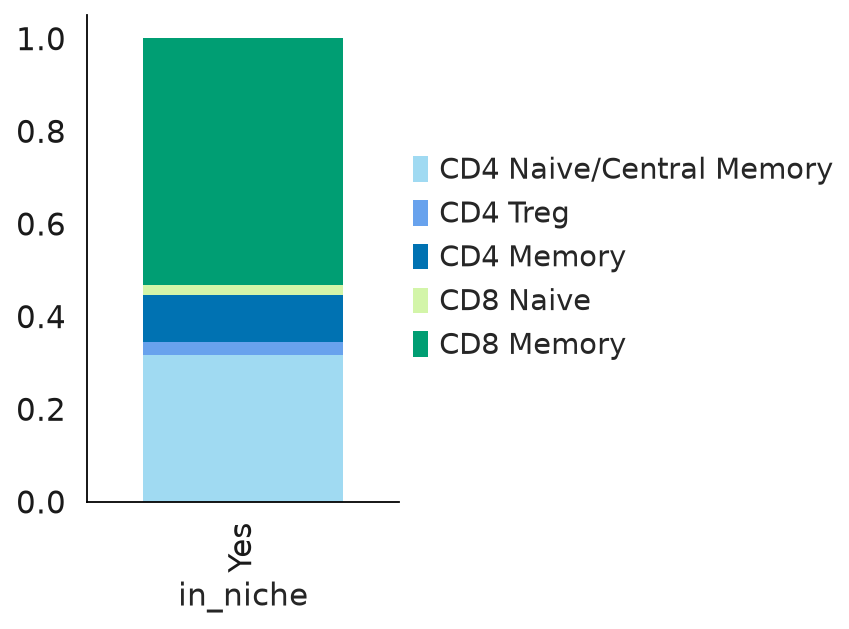

In [6]:
ad_tcell = adata_xenv1[adata_xenv1.obs['ct_general'].isin(['T Cell'])]
ad_tcell = ad_tcell[ad_tcell.obs['diagnosis'].isin(['MDS-LB','MDS-IB1','MDS-IB2'])]
ad_tcell.obs['in_niche'] = 'No'
ad_tcell.obs.loc[[x for x in allcells if x in ad_tcell.obs.index], 'in_niche'] = 'Yes'

ad_tcell = ad_tcell[ad_tcell.obs['in_niche'] == 'Yes']
sc.set_figure_params(figsize=(2.5, 4))

df = pd.crosstab(index=ad_tcell.obs['in_niche'], columns=ad_tcell.obs['ct_refined'])

df = df.apply(lambda x: x/x.sum(), axis=1)
cols = ["#009E73", '#d3f5a9', "#0072B2", "#68a2ed","#a0daf2"]
cols.reverse()
cmp = matplotlib.colors.ListedColormap(cols)
df = df.loc[:, ['CD4 Naive/Central Memory','CD4 Treg','CD4 Memory','CD8 Naive','CD8 Memory']]
g = df.plot(kind='bar', stacked=True, width = 0.9, colormap= cmp, edgecolor= 'none')
g.spines['top'].set_visible(False)
g.spines['right'].set_visible(False)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.grid(False)
plt.show()


In [13]:
ad_tcell = adata_xenv1[adata_xenv1.obs['ct_general'].isin(['T Cell'])]
ad_tcell = ad_tcell[ad_tcell.obs['diagnosis'].isin(['MDS-LB','MDS-IB1','MDS-IB2'])]
ad_tcell.obs['in_niche'] = 'No'
ad_tcell.obs.loc[[x for x in allcells if x in ad_tcell.obs.index], 'in_niche'] = 'Yes'

ad_tcell = ad_tcell[~(ad_tcell.obs['in_niche'] == 'NA')]

###### ISG signature 
sig_df = None
for samp in ad_tcell.obs['study_id'].unique():
    print(samp)
    currsamp = ad_tcell[ad_tcell.obs['study_id'] == samp].copy()
    score_genes({'cyto' : ['GNLY','GZMB','KLRG1','NKG7','PRF1','TBX21']}, currsamp)

    if (sum(currsamp.obs['in_niche'].value_counts() < 10) > 0) or (len(currsamp.obs['in_niche'].value_counts()) < 2):
        print('skipped')
        continue
    else:        
        print(pd.crosstab(index=currsamp.obs["ct_refined"], columns=currsamp.obs["in_niche"]))
        print(currsamp.obs.groupby(['in_niche'])['zscore_cyto'].agg(['mean']))
        currdf = currsamp.obs.groupby(['in_niche'])['zscore_cyto'].agg(['mean'])
        currdf['sample'] = samp
        sig_df = pd.concat([sig_df, currdf])

sig_df['in_niche'] = sig_df.index


MDS-8
in_niche                    No  Yes
ct_refined                         
CD4 Memory                1481    6
CD4 Naive/Central Memory  2970    4
CD4 Treg                   213    3
CD8 Memory                4959    7
CD8 Naive                  390    2
              mean
in_niche          
No       -0.000139
Yes       0.063308
MDS-1
skipped
MDS-2
skipped
MDS-3
skipped
MDS-6
in_niche                   No  Yes
ct_refined                        
CD4 Memory                173    1
CD4 Naive/Central Memory  584    3
CD4 Treg                   61    1
CD8 Memory                816    6
CD8 Naive                  33    0
              mean
in_niche          
No        0.001577
Yes      -0.238998
MDS-25
in_niche                   No  Yes
ct_refined                        
CD4 Memory                 39    0
CD4 Naive/Central Memory  492    7
CD4 Treg                   10    0
CD8 Memory                306    7
CD8 Naive                  22    1
              mean
in_niche          
No     

In [14]:
sig_df

,mean,sample,in_niche
in_niche,,,
No,-1.390960e-04,MDS-8,No
Yes,6.330763e-02,MDS-8,Yes
No,1.577073e-03,MDS-6,No
Yes,-2.389982e-01,MDS-6,Yes
No,-4.373146e-04,MDS-25,No
Yes,2.533509e-02,MDS-25,Yes
No,2.045366e-04,MDS-9,No
Yes,-1.396985e-01,MDS-9,Yes
No,2.182183e-03,MDS-5,No


<Axes: xlabel='in_niche', ylabel='mean'>

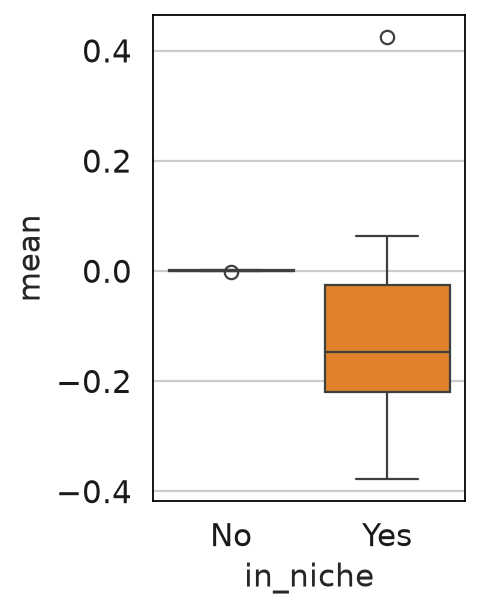

In [15]:
sns.boxplot(data=sig_df, x='in_niche', y='mean', hue='in_niche')


## ED Figure 4c. Enrichment near megakaryocyte (log2FC heatmap, Control and MDS)


In [52]:
di_diagnosis = dict(zip(adata_xenv1.obs['study_id'], adata_xenv1.obs['diagnosis']))
meganeighs = adata_xenv1[adata_xenv1.obs['mega_neigh'] != 'NA']
meganeigh_ct = pd.crosstab(index=meganeighs.obs['study_id'], columns=meganeighs.obs['ct_general']).apply(lambda x: x/x.sum(), axis=1)

meganeigh_ct['diagnosis'] = [di_diagnosis[x] for x in meganeigh_ct.index]
ad_nomeg = adata_xenv1[adata_xenv1.obs['ct_general'] != 'Megakaryocyte']
global_ct = pd.crosstab(index=ad_nomeg.obs['study_id'], columns=ad_nomeg.obs['ct_general']).apply(lambda x: x/x.sum(), axis=1)
global_ct['diagnosis'] = [di_diagnosis[x] for x in global_ct.index]

mds_cats = ['MDS-LB','MDS-IB1','MDS-IB2']
control_cats = ['Control-Donor','Control-Lymph']

def neighbor_enrichment(group_name, cats):
    rows = []
    for ct in adata_xenv1.obs['ct_general'].unique():
        if ct in ['Megakaryocyte']:
            continue
        neigh = meganeigh_ct[meganeigh_ct['diagnosis'].isin(cats)][ct]
        glob = global_ct[global_ct['diagnosis'].isin(cats)][ct]
        log2fc = np.log2(neigh.mean() / glob.mean())
        statistic, p_value = stats.wilcoxon(neigh, glob)
        rows.append({'ct': ct, 'group': group_name, 'log2fc': log2fc, 'pval': p_value})
    return rows

res_df = pd.DataFrame(
    neighbor_enrichment('MDS', mds_cats) + neighbor_enrichment('Control', control_cats),
    columns=['ct', 'group', 'log2fc', 'pval']
)
print(res_df)

                     ct    group    log2fc          pval
0             Erythroid      MDS -0.033778  7.352257e-02
1   Late/Mature Myeloid      MDS -0.028052  5.378507e-01
2                T Cell      MDS  0.091150  1.694011e-03
3           Endothelial      MDS  0.158081  7.543199e-03
4         Early Myeloid      MDS -0.116017  1.830900e-05
5            Macrophage      MDS  0.298895  8.221832e-10
6   Mesenchymal/Stromal      MDS  0.175796  4.831136e-07
7                B Cell      MDS -0.032267  4.881037e-01
8                   pDC      MDS  0.078895  1.130154e-02
9             Adipocyte      MDS -0.363481  1.044132e-02
10                   NK      MDS -0.113396  3.219649e-01
11          Plasma Cell      MDS  0.025015  4.035956e-01
12           Osteoblast      MDS -0.132206  4.800553e-01
13                 Mast      MDS -0.091905  3.094649e-01
14                 HSPC      MDS  0.039479  3.041748e-02
15                 VSMC      MDS -0.002688  9.081598e-01
16            Erythroid  Contro

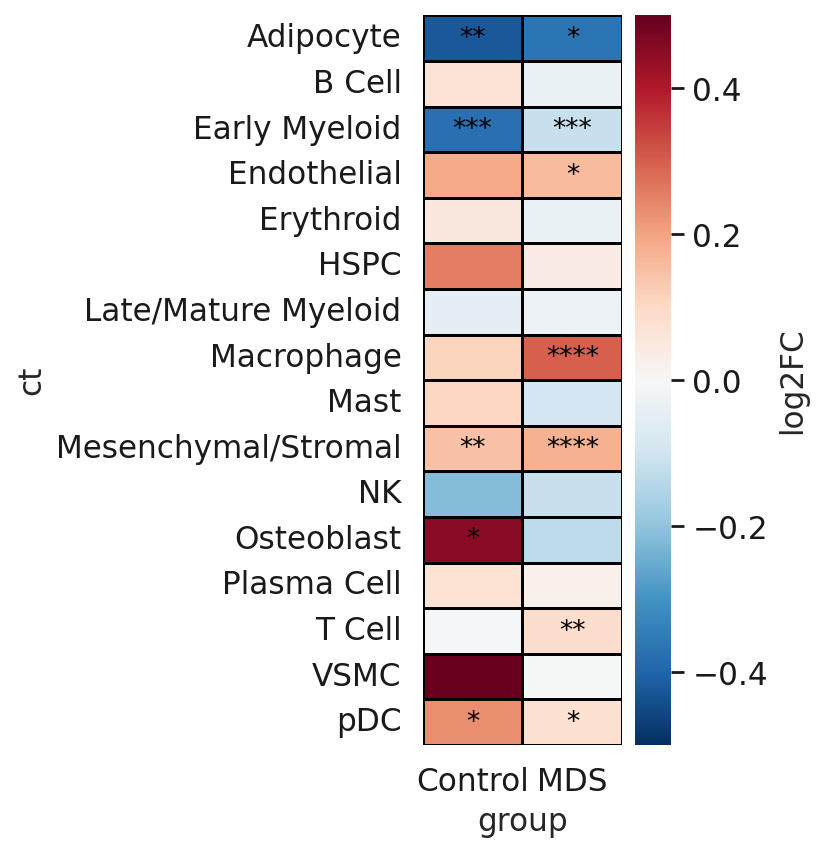

In [57]:
from statsmodels.stats.multitest import multipletests
reject, adjusted, _, _ = multipletests(res_df['pval'], alpha=0.05, method='fdr_bh')
res_df['padj'] = adjusted

# Create significance labels
def p_to_star(p):
    if p < 0.0001:
        return '****'
    elif p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    else:
        return ''
res_df['label'] = res_df['padj'].apply(p_to_star)

# Pivot to wide format
mat = res_df.pivot(index='ct', columns='group', values='log2fc')
label_mat = res_df.pivot(index='ct', columns='group', values='label')

# Make heatmap
plt.figure(figsize=(2, 6))
sns.heatmap(
    mat, annot=label_mat, fmt='',               
    cmap='RdBu_r', center=0,             
    cbar_kws={'label': 'log2FC'},linewidths=0.5, vmin = -0.5,vmax = 0.5,
    linecolor='black', annot_kws={'color': 'black', 'fontsize':12}
)

plt.grid(False)
plt.tight_layout()
plt.show()

## ED Figure 4e. Lymphocyte nearest-neighbour enrichment z-score, Control vs MDS (split triangle)


In [59]:
remove_samples = ['region2_0042591', 'region2_0078981', 'region1_0078989', 'region4_0065604']
adata_xenv1.obs['ct_refined1'] = adata_xenv1.obs['ct_refined']

enrichment_di_MDS = dict() 
samples = adata_xenv1.obs['sample_name'][adata_xenv1.obs['diagnosis'].isin(['MDS-LB', 'MDS-IB1', 'MDS-IB2'])].unique()
for samp in samples: 
    print(samp)
    tmp = adata_xenv1[adata_xenv1.obs['sample_name'] == samp]
    sq.gr.spatial_neighbors(tmp,n_neighs=5)
    sq.gr.nhood_enrichment(tmp, cluster_key="ct_refined1")
    ct_order = list(tmp.obs['ct_refined1'].cat.categories)
    for ct in list(tmp.obs['ct_refined1'].cat.categories):
        for i,score in enumerate(list(tmp.uns['ct_refined1_nhood_enrichment']['zscore'][list(tmp.obs['ct_refined1'].cat.categories).index(ct)])):
            if not (ct, ct_order[i]) in enrichment_di_MDS:
                enrichment_di_MDS[(ct, ct_order[i])] = []
            enrichment_di_MDS[(ct, ct_order[i])].append(score)

enrichment_di_control = dict() 
samples = adata_xenv1.obs['sample_name'][adata_xenv1.obs['diagnosis'].isin(['Control-Donor', 'Control-Lymph'])].unique()
samples = [x for x in samples if not x in remove_samples]
for samp in samples: 
    print(samp)
    tmp = adata_xenv1[adata_xenv1.obs['sample_name'] == samp]
    sq.gr.spatial_neighbors(tmp,n_neighs=5)
    sq.gr.nhood_enrichment(tmp, cluster_key="ct_refined1")
    ct_order = list(tmp.obs['ct_refined1'].cat.categories)
    for ct in list(tmp.obs['ct_refined1'].cat.categories):
        for i,score in enumerate(list(tmp.uns['ct_refined1_nhood_enrichment']['zscore'][list(tmp.obs['ct_refined1'].cat.categories).index(ct)])):
            if not (ct, ct_order[i]) in enrichment_di_control:
                enrichment_di_control[(ct, ct_order[i])] = []
            enrichment_di_control[(ct, ct_order[i])].append(score)


region1_0011549


  0%|          | 0/1000 [00:00<?, ?/s]

region1_0011552


  0%|          | 0/1000 [00:00<?, ?/s]

region2_0011552


  0%|          | 0/1000 [00:00<?, ?/s]

... (102 outputs left out)

region2_0079269


  0%|          | 0/1000 [00:00<?, ?/s]

region1_0079269


  0%|          | 0/1000 [00:00<?, ?/s]

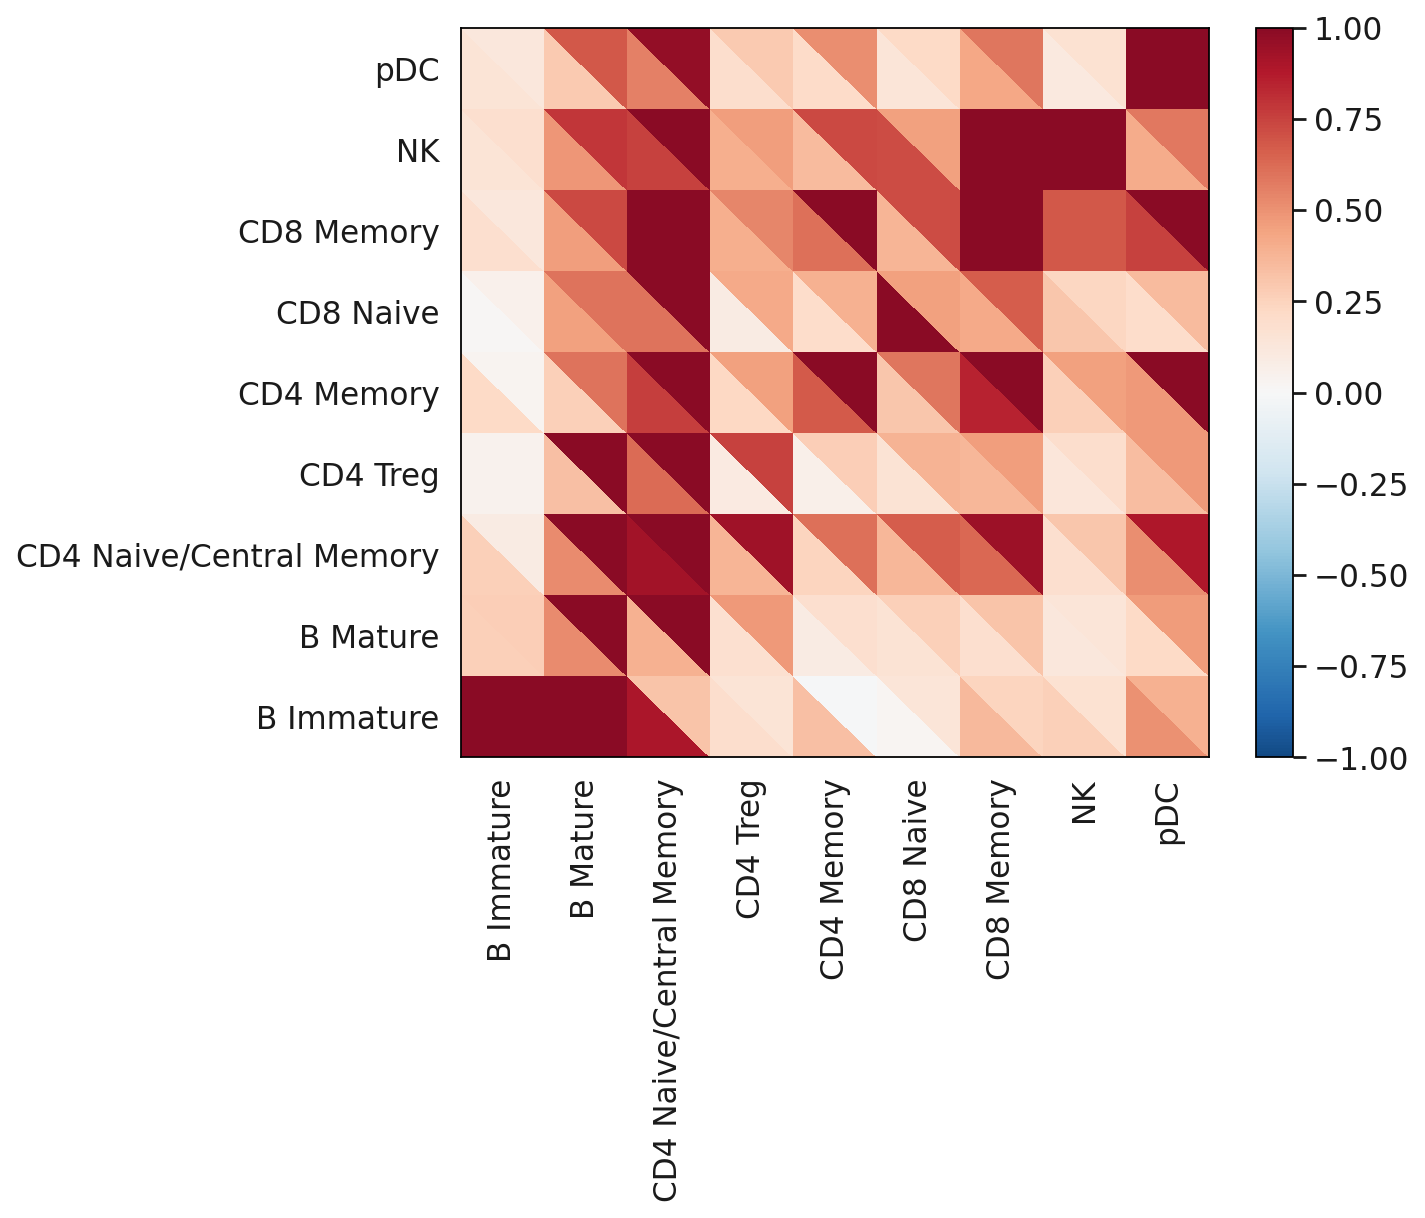

In [60]:
import statistics

ct_order = ['B Immature','B Mature','CD4 Naive/Central Memory', 'CD4 Treg', 'CD4 Memory','CD8 Naive','CD8 Memory', 'NK', 'pDC'] 
tonorm = dict() 
for ct in ct_order:
    tonorm[ct] = []
    for ct2 in ct_order:
        tonorm[ct].extend([x for x in enrichment_di_MDS[(ct, ct2)] if not np.isnan(x)])
        tonorm[ct].extend([x for x in enrichment_di_control[(ct, ct2)] if not np.isnan(x)])

sd_di = dict()
for ct in tonorm:
    sd_di[ct] = statistics.stdev(tonorm[ct])

triangle_MDS_norm2 = []
triangle_control_norm2 = []
for ct in ct_order:
    for ct2 in ct_order:
        values = [x/sd_di[ct] for x in enrichment_di_MDS[(ct, ct2)] if not np.isnan(x)]
        triangle_MDS_norm2.append(sum(values)/len(values))
        values = [x/sd_di[ct] for x in enrichment_di_control[(ct, ct2)] if not np.isnan(x)]
        triangle_control_norm2.append(sum(values)/len(values))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.tri import Triangulation
import matplotlib.colors as colors
import cmasher as cmr
sc.set_figure_params(figsize=(7.5, 6))

M = 9
N = 9
x = np.arange(M + 1)
y = np.arange(N + 1)
xs, ys = np.meshgrid(x, y)
zs = (xs * ys) % 10
zs = zs[:-1, :-1].ravel()

triangles1 = [(i + j*(M+1), i+1 + j*(M+1), i + (j+1)*(M+1)) for j in range(N) for i in range(M)]
triangles2 = [(i+1 + j*(M+1), i+1 + (j+1)*(M+1), i + (j+1)*(M+1)) for j in range(N) for i in range(M)]
triang1 = Triangulation(xs.ravel()-0.5, ys.ravel()-0.5, triangles1)
triang2 = Triangulation(xs.ravel()-0.5, ys.ravel()-0.5, triangles2)

vmin = -1
vmax = 1
norm = colors.TwoSlopeNorm(vmin=vmin, vcenter=0, vmax=vmax)
cmap = cmr.get_sub_cmap('RdBu_r', 0.05, 0.95)

img1 = plt.tripcolor(triang1, triangle_control_norm2, cmap=cmap, norm = norm)
img2 = plt.tripcolor(triang2, triangle_MDS_norm2, cmap=cmap, norm = norm)

plt.colorbar(img1)
plt.xlim(x[0]-0.5, x[-1]-0.5)
plt.ylim(y[0]-0.5, y[-1]-0.5)
plt.xticks(x[:-1], ct_order, rotation=90)
plt.yticks(y[:-1], ct_order) 
plt.show()


## ED Figure 4j. Lymphocyte composition of individual immune aggregates (clustered heatmap)


In [4]:
### dataframe for immune aggregate composition heatmap
tls = adata_xenv1[adata_xenv1.obs['in_tls'] == 'Yes']
df = pd.crosstab(index=tls.obs['tls'], columns=tls.obs['ct_refined']).apply(lambda x: x/x.sum(), axis=1)
from collections import Counter
tls_sizes = Counter(tls.obs['tls'])
df['Size'] = [tls_sizes[x] for x in df.index]
df['group'] = ['Small' if x < 100 else 'Large' for x in df['Size']]
samptype = dict(zip(tls.obs['tls'], tls.obs['diagnosis']))
df['Diagnosis'] = [samptype[x] for x in df.index]
df['group'] = [df['Diagnosis'][i].split('-')[0] + ' ' + df['group'][i] for i in range(df.shape[0])]
df

ct_refined,B Immature,B Mature,CD4 Memory,CD4 Naive/Central Memory,CD4 Treg,CD8 Memory,CD8 Naive,NK,pDC,Size,group,Diagnosis
tls,,,,,,,,,,,,
137_54,0.008333,0.350000,0.041667,0.258333,0.033333,0.175000,0.041667,0.041667,0.050000,120,MDS Large,MDS-IB1
283_54,0.000000,0.000000,0.235294,0.294118,0.000000,0.294118,0.000000,0.000000,0.176471,17,MDS Small,MDS-IB1
455_54,0.000000,0.000000,0.058824,0.411765,0.000000,0.235294,0.117647,0.058824,0.117647,17,MDS Small,MDS-IB1
479_27,0.000000,0.000000,0.096774,0.096774,0.032258,0.548387,0.000000,0.000000,0.225806,31,MDS Small,MDS-IB1
613_28,0.000000,0.166667,0.047619,0.190476,0.071429,0.238095,0.047619,0.119048,0.119048,42,MDS Small,MDS-LB
...,...,...,...,...,...,...,...,...,...,...,...,...
717820_10,0.000000,0.000000,0.000000,0.181818,0.000000,0.545455,0.181818,0.090909,0.000000,11,MDS Small,MDS-LB
741621_10,0.000000,0.000000,0.117647,0.235294,0.000000,0.352941,0.117647,0.176471,0.000000,17,MDS Small,MDS-LB
793712_10,0.000000,0.000000,0.062500,0.125000,0.000000,0.437500,0.062500,0.125000,0.187500,16,MDS Small,MDS-LB


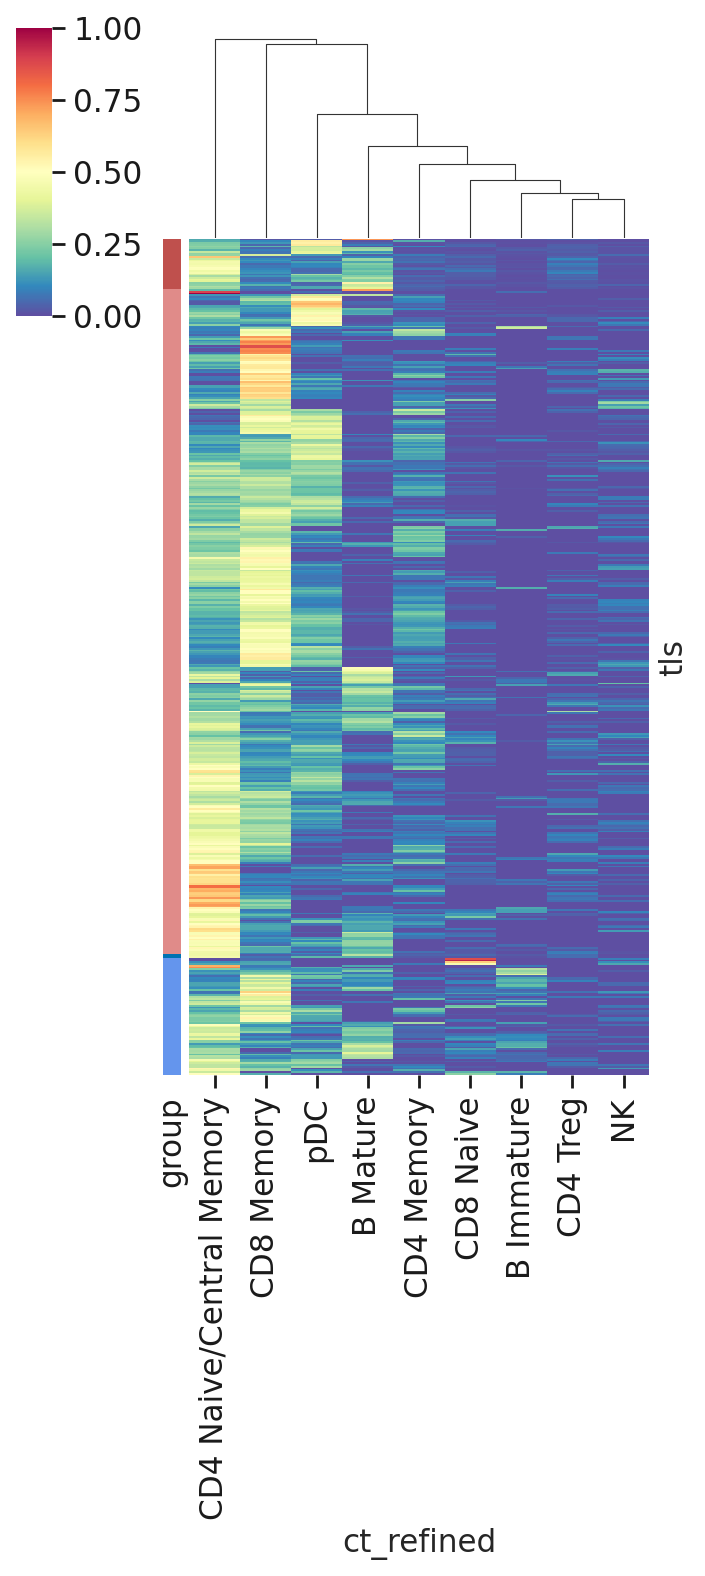

In [6]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns; sns.set_theme(color_codes=True)
import cmasher as cmr
sc.set_figure_params(figsize=(8, 10))
matplotlib.rcParams['pdf.fonttype'] = 42

lut = {'MDS Small': "#e08b89", 'MDS Large': "#BF504D", 'Control Small': "#6495ed", 'Control Large': "#0072B2"}
cmap = 'Spectral_r'

def get_row_order(tmp):
    row_colors = tmp['group'].map(lut)
    g = sns.clustermap(tmp.iloc[:, :-3], row_cluster=True, yticklabels=False,
                       xticklabels=True, cmap=cmap, figsize=(6, 10), row_colors=row_colors)
    order = tmp.index[g.dendrogram_row.reordered_ind]
    plt.close(g.fig)
    return order

roworder_large = get_row_order(df[df['group'] == 'MDS Large'])
roworder_small = get_row_order(df[df['group'] == 'MDS Small'])

tmp = df[df['group'] == 'Control Small']
roworder_controlsmall = get_row_order(tmp[tmp['Diagnosis'] != 'Control-TP'])

tmp = df[df['group'] == 'Control Large']
roworder_controllarge = get_row_order(tmp[tmp['Diagnosis'] != 'Control-TP'])

roworder = [x for x in roworder_large] + [x for x in roworder_small] + [x for x in roworder_controllarge] + [x for x in roworder_controlsmall]
df = df.loc[roworder]
row_colors = df['group'].map(lut)
g = sns.clustermap(df.iloc[:, :-3], row_cluster=False, yticklabels=False,
                   xticklabels=True, cmap=cmap, figsize=(4.5, 10), row_colors=row_colors)
g.ax_heatmap.tick_params(right=False, bottom=True)

plt.show()